# 15. Guralp Certimus (MSFC) instrument correction

Reads the MSFC Guralp Certimus channels for the launch window from the master SDS and removes the
instrument response, so B07 and B12 can join the quantitative amplitude comparisons.

* **B07**: `DG_B07.dataless`, downloaded with the B07 data (20260403 service run).
* **B12**: `Sensor1.xml`, exported from the B12 digitizer during the 20260310 service run.

(This replaces `for_guralp_marketing.ipynb`, which corrected B07 with the B12 response.)
The Silicon Audio channels at B23 (`DG.B23.01.CL?`) still have no response file.

In [1]:
from obspy import Stream, read_inventory

import artemis2_config as cfg

st_raw = cfg.get_group_stream('MSFC').select(channel='CH?')
print(st_raw)
inventories = {sta: read_inventory(str(p)) for sta, p in cfg.GURALP_INVENTORIES.items()}
for sta, inv in inventories.items():
    print(sta, cfg.GURALP_INVENTORIES[sta].name, inv.select(station=sta, channel='CH?').get_contents()['channels'])

4 Trace(s) in Stream:
DG.B07.1L.CHZ | 2026-04-01T22:05:12.000000Z - 2026-04-01T23:20:12.000000Z | 500.0 Hz, 2250001 samples
DG.B12.1L.CHE | 2026-04-01T22:30:00.534000Z - 2026-04-01T22:45:01.776000Z | 500.0 Hz, 450622 samples
DG.B12.1L.CHN | 2026-04-01T22:30:05.202000Z - 2026-04-01T22:45:04.946000Z | 500.0 Hz, 449873 samples
DG.B12.1L.CHZ | 2026-04-01T22:30:04.532000Z - 2026-04-01T22:44:57.758000Z | 500.0 Hz, 446614 samples


B07 DG_B07.dataless ['DG.B07.1J.CHE', 'DG.B07.1J.CHN', 'DG.B07.1J.CHZ', 'DG.B07.1L.CHE', 'DG.B07.1L.CHN', 'DG.B07.1L.CHZ', 'DG.B07.1N.CHE', 'DG.B07.1N.CHN', 'DG.B07.1N.CHZ']
B12 Sensor1.xml ['DG.B12.1J.CHE', 'DG.B12.1J.CHN', 'DG.B12.1J.CHZ', 'DG.B12.1L.CHE', 'DG.B12.1L.CHN', 'DG.B12.1L.CHZ', 'DG.B12.1N.CHE', 'DG.B12.1N.CHN', 'DG.B12.1N.CHZ']


## Remove response to ground velocity

4 Trace(s) in Stream:
DG.B07.1L.CHZ | 2026-04-01T22:05:12.000000Z - 2026-04-01T23:20:12.000000Z | 500.0 Hz, 2250001 samples
DG.B12.1L.CHE | 2026-04-01T22:30:00.534000Z - 2026-04-01T22:45:01.776000Z | 500.0 Hz, 450622 samples
DG.B12.1L.CHN | 2026-04-01T22:30:05.202000Z - 2026-04-01T22:45:04.946000Z | 500.0 Hz, 449873 samples
DG.B12.1L.CHZ | 2026-04-01T22:30:04.532000Z - 2026-04-01T22:44:57.758000Z | 500.0 Hz, 446614 samples


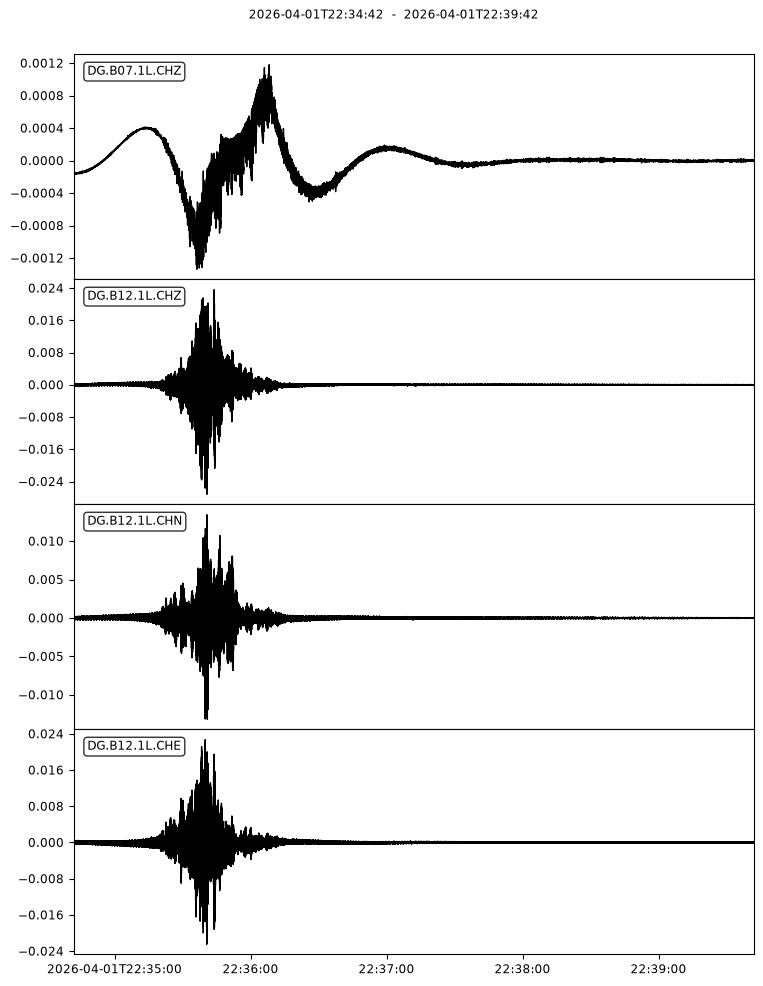

In [2]:
st_vel = Stream()
for tr in st_raw.copy():
    inv = inventories[tr.stats.station]
    nyq = 0.5 * tr.stats.sampling_rate
    tr.remove_response(inventory=inv, output='VEL',
                       pre_filt=(0.01, 0.02, 0.94 * nyq, 0.98 * nyq),
                       zero_mean=True, taper=True)
    tr.stats['corrected'] = True
    st_vel += tr
print(st_vel)
st_vel.plot(equal_scale=False, starttime=cfg.STARTTRIM, endtime=cfg.ENDTRIM);

In [3]:
for tr in st_vel:
    seg = tr.slice(cfg.STARTTRIM, cfg.ENDTRIM)
    print(f'{tr.id}: peak |v| = {abs(seg.data).max():.3e} m/s')

DG.B07.1L.CHZ: peak |v| = 1.338e-03 m/s
DG.B12.1L.CHE: peak |v| = 2.270e-02 m/s
DG.B12.1L.CHN: peak |v| = 1.344e-02 m/s
DG.B12.1L.CHZ: peak |v| = 2.717e-02 m/s


## Spectrograms (vertical channels)

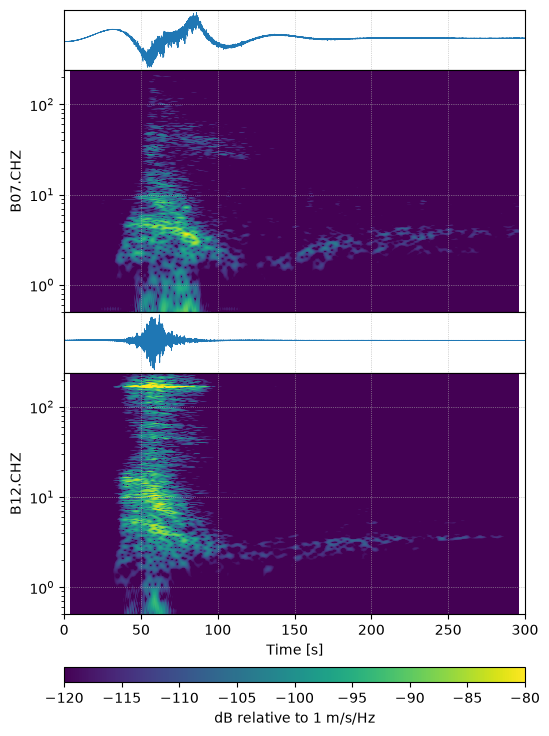

In [4]:
from flovopy.processing.spectrograms import icewebSpectrogram

st_z = st_vel.select(component='Z').copy().trim(cfg.STARTTRIM, cfg.ENDTRIM)
spobj = icewebSpectrogram(st_z, secsPerFFT=10.24)
spobj.plot(fmax=240, log=True, dbscale=True, equal_scale=True, clim=[1e-6, 1e-4]);

## Save corrected Guralp stream

In [5]:
out = cfg.OUT_DIR / 'guralp_stream_corrected.mseed'
st_vel.write(str(out), format='MSEED')
print('wrote', out)

wrote /private/tmp/claude-502/-Users-glennthompson-Developer-KSCRocketSeismoHydrology/4dc49c3a-68d5-404e-9b29-5d4ef15c5417/scratchpad/out25/guralp_stream_corrected.mseed


/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/io/mseed/core.py:1043: UserWarning: The encoding specified in trace.stats.mseed.encoding does not match the dtype of the data.
A suitable encoding will be chosen.
  warnings.warn(msg, UserWarning)
